# EDA — NEURFIT Smart Wardrobe

Notebook ini adalah versi **step-by-step** dari `01_eda_check.py`.
Kode di setiap sel sama dengan skrip; fungsi `main()` dipecah menjadi langkah-langkah.

| Step | Isi |
|---|---|
| 0 | Setup & import |
| 1 | Fungsi `dhash` |
| 2 | Siapkan folder output & label |
| 3 | Baca `styles.csv` |
| 4 | Cek ketersediaan gambar |
| 5 | Hitung dHash & duplikat persis |
| 6 | Coverage mapping label |
| 7 | Inventaris kategori Re-PolyVore |
| 8 | Rekonstruksi set dari nama file |
| 9 | Cek template outfit lengkap |
| 10 | Simpan `eda_summary.json` |

## Step 0 — Setup & import

In [1]:
# Bootstrap: pastikan working directory = folder ml/ (pengganti Path(__file__))
import os
import sys
from pathlib import Path

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
sys.path.insert(0, str(ML_DIR))
print("working dir:", ML_DIR)

working dir: C:\NEURFIT_PROJECT\ml


In [2]:
import json
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import config_utils as cu

## Step 1 — Fungsi `dhash`

Mengubah gambar menjadi fingerprint 64-bit (difference hash) untuk mendeteksi duplikat persis.

In [3]:
def dhash(path: Path, size: int = 8) -> int:
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("L").resize(
            (size + 1, size), Image.Resampling.LANCZOS
        )
        arr = np.asarray(im, dtype=np.int16)
    bits = (arr[:, 1:] > arr[:, :-1]).reshape(-1)
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return value

## Step 2 — Siapkan folder output & muat label

In [4]:
out_dir = cu.ensure_dir(cu.artifact_dir() / "eda")
processed = cu.ensure_dir(cu.fashion_processed_dir())
labels = cu.load_labels()
print("out_dir  :", cu.to_posix(out_dir))
print("processed:", cu.to_posix(processed))
print("labels version:", labels.get("version"))

out_dir  : C:/NEURFIT_PROJECT/ml/artifacts/eda
processed: C:/NEURFIT_PROJECT/ml/data/processed
labels version: labels-v1


## Step 3 — Baca katalog `styles.csv`

In [5]:
styles_path = cu.fashion_raw_dir() / "styles.csv"
images_dir = cu.fashion_raw_dir() / "images"
styles = pd.read_csv(styles_path, on_bad_lines="skip")
print(f"styles rows: {len(styles)} | columns: {len(styles.columns)}")
print(f"styles path: {cu.to_posix(styles_path)}")
styles.head()

styles rows: 44424 | columns: 10
styles path: C:/NEURFIT_PROJECT/ml/data/fashionProduct/styles.csv


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


## Step 4 — Cek ketersediaan gambar

In [6]:
id_num = pd.to_numeric(styles["id"], errors="coerce")
image_ok = pd.Series(False, index=styles.index)
valid_positions = id_num.notna()
image_ok.loc[valid_positions] = [
    (images_dir / f"{int(i)}.jpg").exists() for i in id_num.loc[valid_positions]
]
print(f"images present: {int(image_ok.sum())} | missing: {int((~image_ok).sum())}")

images present: 44419 | missing: 5


## Step 5 — Hitung dHash & duplikat persis

Hasil disimpan ke `data/processed/fashion_dhash.csv` (dipakai preprocessing).

In [7]:
hashes = []
hash_rows = []
for row in styles.loc[image_ok, ["id"]].itertuples(index=False):
    path = images_dir / f"{int(row.id)}.jpg"
    try:
        value = dhash(path)
    except Exception:
        continue
    hashes.append(value)
    hash_rows.append({"id": int(row.id), "dhash": f"{value:016x}"})
hash_df = pd.DataFrame(hash_rows)
hash_df.to_csv(processed / "fashion_dhash.csv", index=False)
unique_hashes = len(set(hashes))
print(f"exact dHash duplicates: {len(hashes) - unique_hashes} "
      f"of {len(hashes)} images")

exact dHash duplicates: 2894 of 44419 images


## Step 6 — Coverage mapping label

Label mentah dipetakan ke taksonomi `configs/labels.yaml`.

In [8]:
article_map = {
    e["dataset"]: e["key"]
    for e in labels["article_type"]
    if e.get("dataset")
}
colour_map = {
    ds: e["key"] for e in labels["base_colour"] for ds in e["dataset"]
}
usage_map = {
    ds: e["key"] for e in labels["usage"] for ds in e["dataset"]
}
mapped_article = styles["articleType"].map(article_map)
mapped_colour = styles["baseColour"].map(colour_map)
mapped_usage = styles["usage"].map(usage_map)
print(f"articleType mapped: {int(mapped_article.notna().sum())} | "
      f"other: {int(mapped_article.isna().sum())}")
print(f"baseColour mapped: {int(mapped_colour.notna().sum())} | "
      f"unmapped: {int(mapped_colour.isna().sum())}")
print(f"usage mapped: {int(mapped_usage.notna().sum())} | "
      f"masked: {int(mapped_usage.isna().sum())}")
print("season:", styles["season"].value_counts(dropna=False).to_dict())
print("usage raw:", styles["usage"].value_counts(dropna=False).to_dict())

articleType mapped: 31047 | other: 13377
baseColour mapped: 44180 | unmapped: 244
usage mapped: 40898 | masked: 3526
season: {'Summer': 21472, 'Fall': 11431, 'Winter': 8517, 'Spring': 2983, nan: 21}
usage raw: {'Casual': 34406, 'Sports': 4025, 'Ethnic': 3208, 'Formal': 2345, nan: 317, 'Smart Casual': 67, 'Party': 29, 'Travel': 26, 'Home': 1}


## Step 7 — Inventaris kategori Re-PolyVore

In [9]:
poly_root = cu.polyvore_raw_dir() / "Re-PolyVore"
categories = sorted(d.name for d in poly_root.iterdir() if d.is_dir())
category_counts = {
    name: sum(1 for _ in (poly_root / name).glob("*.jpg"))
    for name in categories
}
print("polyvore categories:", category_counts)

polyvore categories: {'bag': 21268, 'bracelet': 5174, 'brooch': 995, 'dress': 7479, 'earrings': 5508, 'eyewear': 6680, 'gloves': 386, 'hairwear': 692, 'hats': 2913, 'jumpsuit': 296, 'legwear': 202, 'necklace': 4664, 'neckwear': 1189, 'outwear': 10169, 'pants': 8957, 'rings': 3227, 'shoes': 20135, 'skirt': 5307, 'top': 19397, 'watches': 2290}


## Step 8 — Rekonstruksi set dari nama file

Layout: `Re-PolyVore/{category}/{set_id}_{index}.jpg`.

In [10]:
sets: dict[str, dict[str, list[tuple[int, Path, str]]]] = defaultdict(
    lambda: defaultdict(list)
)
bad_names = 0
total_jpg = 0
for category in categories:
    for path in (poly_root / category).glob("*.jpg"):
        total_jpg += 1
        stem = path.stem
        if "_" not in stem:
            bad_names += 1
            continue
        set_id, raw_index = stem.rsplit("_", 1)
        try:
            index = int(raw_index)
        except ValueError:
            bad_names += 1
            continue
        sets[set_id][category].append((index, path, category))
print(f"total jpg: {total_jpg} | bad names: {bad_names} | set ids: {len(sets)}")

total jpg: 126928 | bad names: 277 | set ids: 31333


## Step 9 — Cek template outfit lengkap

- **classic**: top/outwear + pants/skirt + shoes
- **dress**: dress/jumpsuit + shoes

In [11]:
top = {"top", "outwear"}
bottom = {"pants", "skirt"}
shoes = {"shoes"}
one_piece = {"dress", "jumpsuit"}

complete = 0
dress_complete = 0
selected_items = 0
for set_id, by_cat in sets.items():
    cats = set(by_cat)
    classic = bool(cats & top) and bool(cats & bottom) and bool(cats & shoes)
    dress = bool(cats & one_piece) and bool(cats & shoes)
    if classic or dress:
        complete += 1
        if dress and not classic:
            dress_complete += 1
        selected_items += sum(len(by_cat[c]) for c in cats if c in (
            top | bottom | shoes | one_piece | {"bag", "bracelet", "brooch",
            "earrings", "eyewear", "gloves", "hairwear", "hats", "necklace",
            "neckwear", "rings", "watches", "legwear"}
        ))
print(f"complete: {complete} | dress-only: {dress_complete} | selected items: {selected_items}")

complete: 12691 | dress-only: 5130 | selected items: 62324

## Step 10 — Simpan ringkasan EDA

In [12]:
summary = {
    "fashion": {
        "styles_rows": int(len(styles)),
        "images_present": int(image_ok.sum()),
        "images_missing": int((~image_ok).sum()),
        "exact_dhash_duplicates": int(len(hashes) - unique_hashes),
        "article_mapped": int(mapped_article.notna().sum()),
        "article_other": int(mapped_article.isna().sum()),
        "colour_mapped": int(mapped_colour.notna().sum()),
        "colour_unmapped": int(mapped_colour.isna().sum()),
        "usage_mapped": int(mapped_usage.notna().sum()),
        "usage_masked": int(mapped_usage.isna().sum()),
        "season_counts": {str(k): int(v) for k, v in styles["season"].value_counts(dropna=False).items()},
        "usage_counts": {str(k): int(v) for k, v in styles["usage"].value_counts(dropna=False).items()},
    },
    "polyvore": {
        "total_jpg": total_jpg,
        "bad_filenames": bad_names,
        "unique_set_ids": len(sets),
        "complete_templates": complete,
        "dress_only_templates": dress_complete,
        "selected_item_candidates": selected_items,
        "category_counts": category_counts,
    },
}
(out_dir / "eda_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(f"polyvore total jpg: {total_jpg} | sets: {len(sets)} | "
      f"complete templates: {complete} | dress-only: {dress_complete}")
print(f"EDA summary: {cu.to_posix(out_dir / 'eda_summary.json')}")

polyvore total jpg: 126928 | sets: 31333 | complete templates: 12691 | dress-only: 5130
EDA summary: C:/NEURFIT_PROJECT/ml/artifacts/eda/eda_summary.json


---
## Step 11 — Visualisasi & Bukti EDA (untuk Laporan & PPT)

Sel-sel berikut bersifat *self-contained* (membaca langsung `styles.csv`, `labels.yaml`, dan `artifacts/eda/eda_summary.json`) untuk menghasilkan tabel missing value, distribusi dataset Fashion Product Images & Re-PolyVore, serta menyimpan grafik resolusi tinggi ke `artifacts/plots/`.

=== Tabel Missing Values & Kualitas Kolom (styles.csv) ===


,Kolom,Tipe Data,Jumlah Valid,Missing Count,Missing (%),Unique Values
0,usage,object,44107,317,0.714,8
1,season,object,44403,21,0.047,4
2,baseColour,object,44409,15,0.034,46
3,productDisplayName,object,44417,7,0.016,31121
4,year,float64,44423,1,0.002,13
5,id,int64,44424,0,0.000,44424
6,gender,object,44424,0,0.000,5
7,masterCategory,object,44424,0,0.000,7
8,subCategory,object,44424,0,0.000,45
9,articleType,object,44424,0,0.000,143


=== Ringkasan Kualitas Data & Coverage Mapping ===


,Metrik,Jumlah,Persentase
0,Total baris styles.csv,44424,100.00%
1,Gambar tersedia (images_present),44419,99.99%
2,Gambar hilang (images_missing),5,0.01%
3,Duplikat persis (exact dHash),2894,6.52%
4,articleType terpetakan (23 kelas utama),31047,69.89%
5,articleType masuk kelas 'other',13377,30.11%
6,baseColour terpetakan (14 kelas),44180,99.45%
7,usage terpetakan (5 kelas),40898,92.06%
8,usage di-mask (Ethnic/Home/Travel/NaN),3526,7.94%


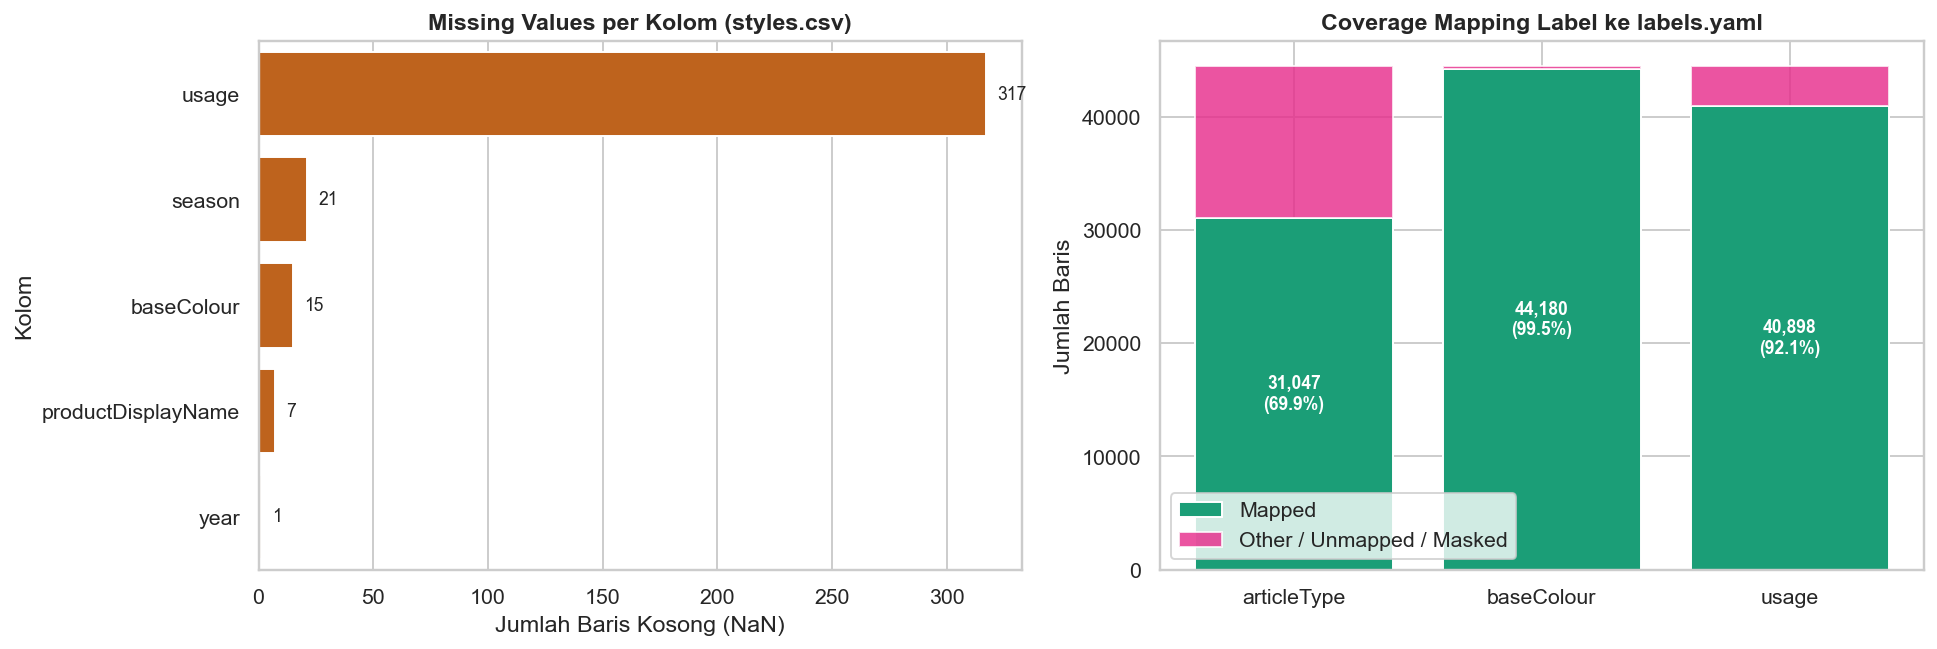

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/eda_missing_coverage.png


In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config_utils as cu

sns.set_theme(style="whitegrid", context="notebook")
PLOT_DIR = cu.ensure_dir(cu.artifact_dir() / "plots")

styles = pd.read_csv(cu.fashion_raw_dir() / "styles.csv", on_bad_lines="skip")
eda_summary = json.loads((cu.artifact_dir() / "eda" / "eda_summary.json").read_text(encoding="utf-8"))

# 1) Tabel Missing Values per kolom di styles.csv
missing_df = pd.DataFrame({
    "Kolom": styles.columns,
    "Tipe Data": [str(styles[c].dtype) for c in styles.columns],
    "Jumlah Valid": [int(styles[c].notna().sum()) for c in styles.columns],
    "Missing Count": [int(styles[c].isna().sum()) for c in styles.columns],
    "Missing (%)": [round(styles[c].isna().mean() * 100, 3) for c in styles.columns],
    "Unique Values": [int(styles[c].nunique(dropna=True)) for c in styles.columns],
}).sort_values("Missing Count", ascending=False).reset_index(drop=True)

print("=== Tabel Missing Values & Kualitas Kolom (styles.csv) ===")
display(missing_df)

# 2) Tabel Ringkasan Kualitas Data & Coverage Label
f_sum = eda_summary["fashion"]
quality_df = pd.DataFrame([
    {"Metrik": "Total baris styles.csv", "Jumlah": f_sum["styles_rows"], "Persentase": "100.00%"},
    {"Metrik": "Gambar tersedia (images_present)", "Jumlah": f_sum["images_present"], "Persentase": f"{f_sum['images_present']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "Gambar hilang (images_missing)", "Jumlah": f_sum["images_missing"], "Persentase": f"{f_sum['images_missing']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "Duplikat persis (exact dHash)", "Jumlah": f_sum["exact_dhash_duplicates"], "Persentase": f"{f_sum['exact_dhash_duplicates']/f_sum['images_present']*100:.2f}%"},
    {"Metrik": "articleType terpetakan (23 kelas utama)", "Jumlah": f_sum["article_mapped"], "Persentase": f"{f_sum['article_mapped']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "articleType masuk kelas 'other'", "Jumlah": f_sum["article_other"], "Persentase": f"{f_sum['article_other']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "baseColour terpetakan (14 kelas)", "Jumlah": f_sum["colour_mapped"], "Persentase": f"{f_sum['colour_mapped']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "usage terpetakan (5 kelas)", "Jumlah": f_sum["usage_mapped"], "Persentase": f"{f_sum['usage_mapped']/f_sum['styles_rows']*100:.2f}%"},
    {"Metrik": "usage di-mask (Ethnic/Home/Travel/NaN)", "Jumlah": f_sum["usage_masked"], "Persentase": f"{f_sum['usage_masked']/f_sum['styles_rows']*100:.2f}%"},
])
print("=== Ringkasan Kualitas Data & Coverage Mapping ===")
display(quality_df)

# Grafik Missing Values & Coverage Label
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), dpi=140)

miss_nonzero = missing_df[missing_df["Missing Count"] > 0]
sns.barplot(data=miss_nonzero, x="Missing Count", y="Kolom", ax=axes[0], color="#d95f02")
axes[0].set_title("Missing Values per Kolom (styles.csv)", fontweight="bold")
axes[0].set_xlabel("Jumlah Baris Kosong (NaN)")
for bar in axes[0].patches:
    w = bar.get_width()
    axes[0].text(w + 5, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9)

cov_labels = ["articleType", "baseColour", "usage"]
mapped_vals = [f_sum["article_mapped"], f_sum["colour_mapped"], f_sum["usage_mapped"]]
unmapped_vals = [f_sum["article_other"], f_sum["colour_unmapped"], f_sum["usage_masked"]]
x = np.arange(len(cov_labels))
axes[1].bar(x, mapped_vals, label="Mapped", color="#1b9e77")
axes[1].bar(x, unmapped_vals, bottom=mapped_vals, label="Other / Unmapped / Masked", color="#e7298a", alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(cov_labels)
axes[1].set_ylabel("Jumlah Baris")
axes[1].set_title("Coverage Mapping Label ke labels.yaml", fontweight="bold")
axes[1].legend()
for i, (m, u) in enumerate(zip(mapped_vals, unmapped_vals)):
    axes[1].text(i, m / 2, f"{m:,}\n({m/(m+u)*100:.1f}%)", ha="center", va="center", color="white", fontweight="bold", fontsize=9)

plt.tight_layout()
fig.savefig(PLOT_DIR / "eda_missing_coverage.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "eda_missing_coverage.png"))

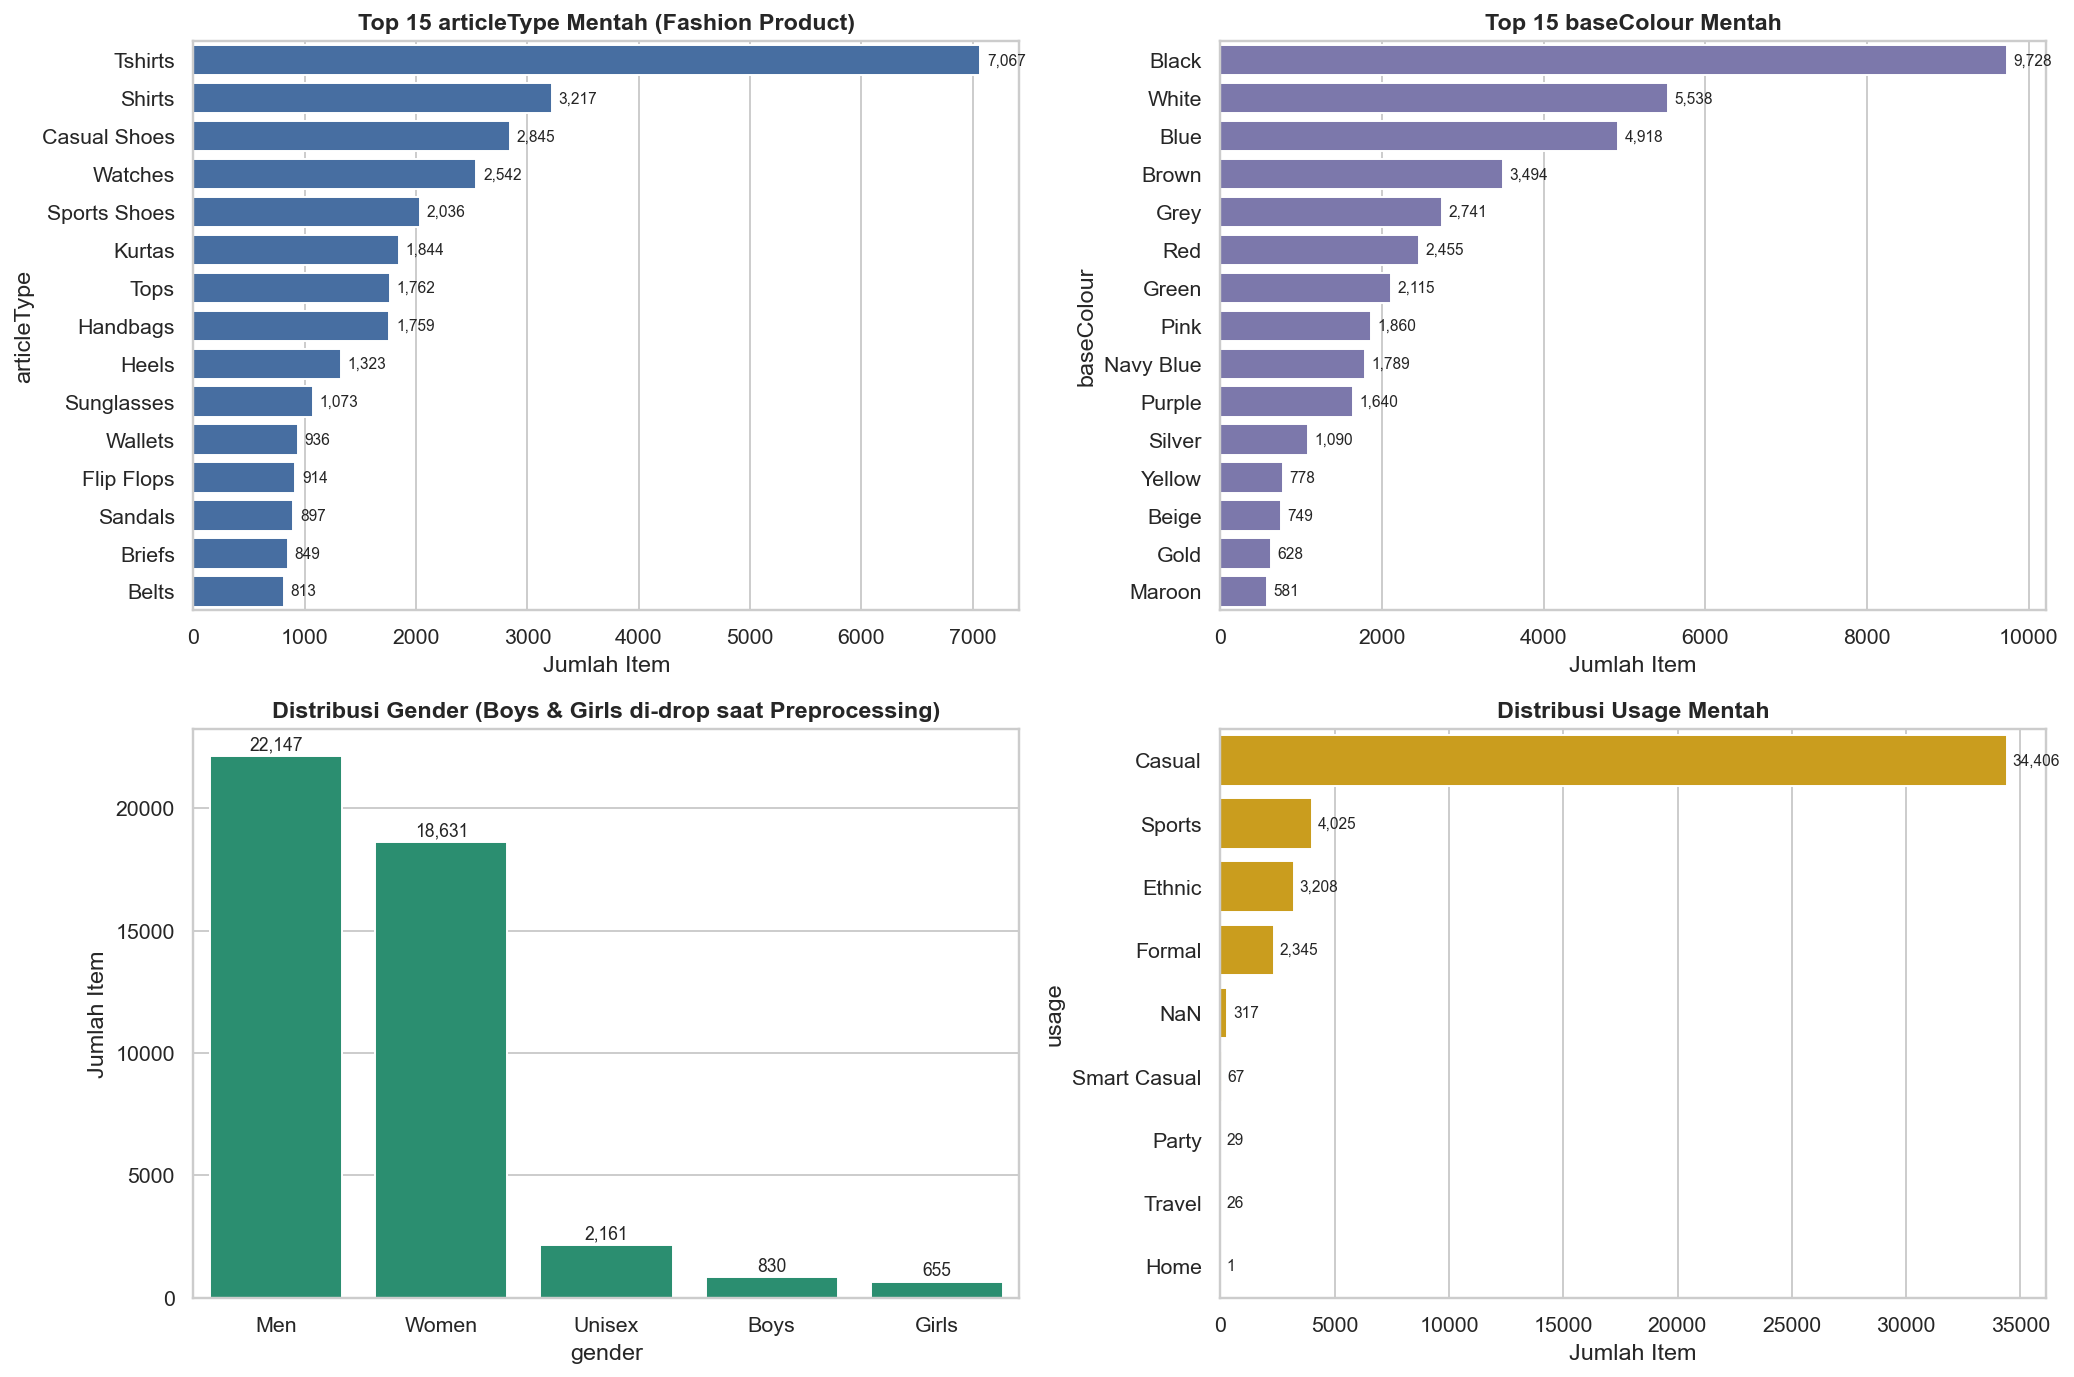

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/eda_fashion_dist.png


In [2]:
# Visualisasi Distribusi Dataset Fashion Product Images (Mentah)
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=140)

# 1. Top 15 articleType
top_art = styles["articleType"].value_counts().head(15)
sns.barplot(x=top_art.values, y=top_art.index, ax=axes[0, 0], color="#386cb0")
axes[0, 0].set_title("Top 15 articleType Mentah (Fashion Product)", fontweight="bold")
axes[0, 0].set_xlabel("Jumlah Item")
for bar in axes[0, 0].patches:
    w = bar.get_width()
    axes[0, 0].text(w + 60, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

# 2. Top 15 baseColour
top_col = styles["baseColour"].value_counts().head(15)
sns.barplot(x=top_col.values, y=top_col.index, ax=axes[0, 1], color="#7570b3")
axes[0, 1].set_title("Top 15 baseColour Mentah", fontweight="bold")
axes[0, 1].set_xlabel("Jumlah Item")
for bar in axes[0, 1].patches:
    w = bar.get_width()
    axes[0, 1].text(w + 80, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

# 3. Distribusi Gender & Season
gender_cnt = styles["gender"].fillna("NaN").value_counts()
sns.barplot(x=gender_cnt.index, y=gender_cnt.values, ax=axes[1, 0], color="#1b9e77")
axes[1, 0].set_title("Distribusi Gender (Boys & Girls di-drop saat Preprocessing)", fontweight="bold")
axes[1, 0].set_ylabel("Jumlah Item")
for bar in axes[1, 0].patches:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, h + 250, f"{int(h):,}", ha="center", fontsize=9)

# 4. Distribusi Usage Mentah
usage_cnt = styles["usage"].fillna("NaN").value_counts()
sns.barplot(x=usage_cnt.values, y=usage_cnt.index, ax=axes[1, 1], color="#e6ab02")
axes[1, 1].set_title("Distribusi Usage Mentah", fontweight="bold")
axes[1, 1].set_xlabel("Jumlah Item")
for bar in axes[1, 1].patches:
    w = bar.get_width()
    axes[1, 1].text(w + 250, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

plt.tight_layout()
fig.savefig(PLOT_DIR / "eda_fashion_dist.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "eda_fashion_dist.png"))

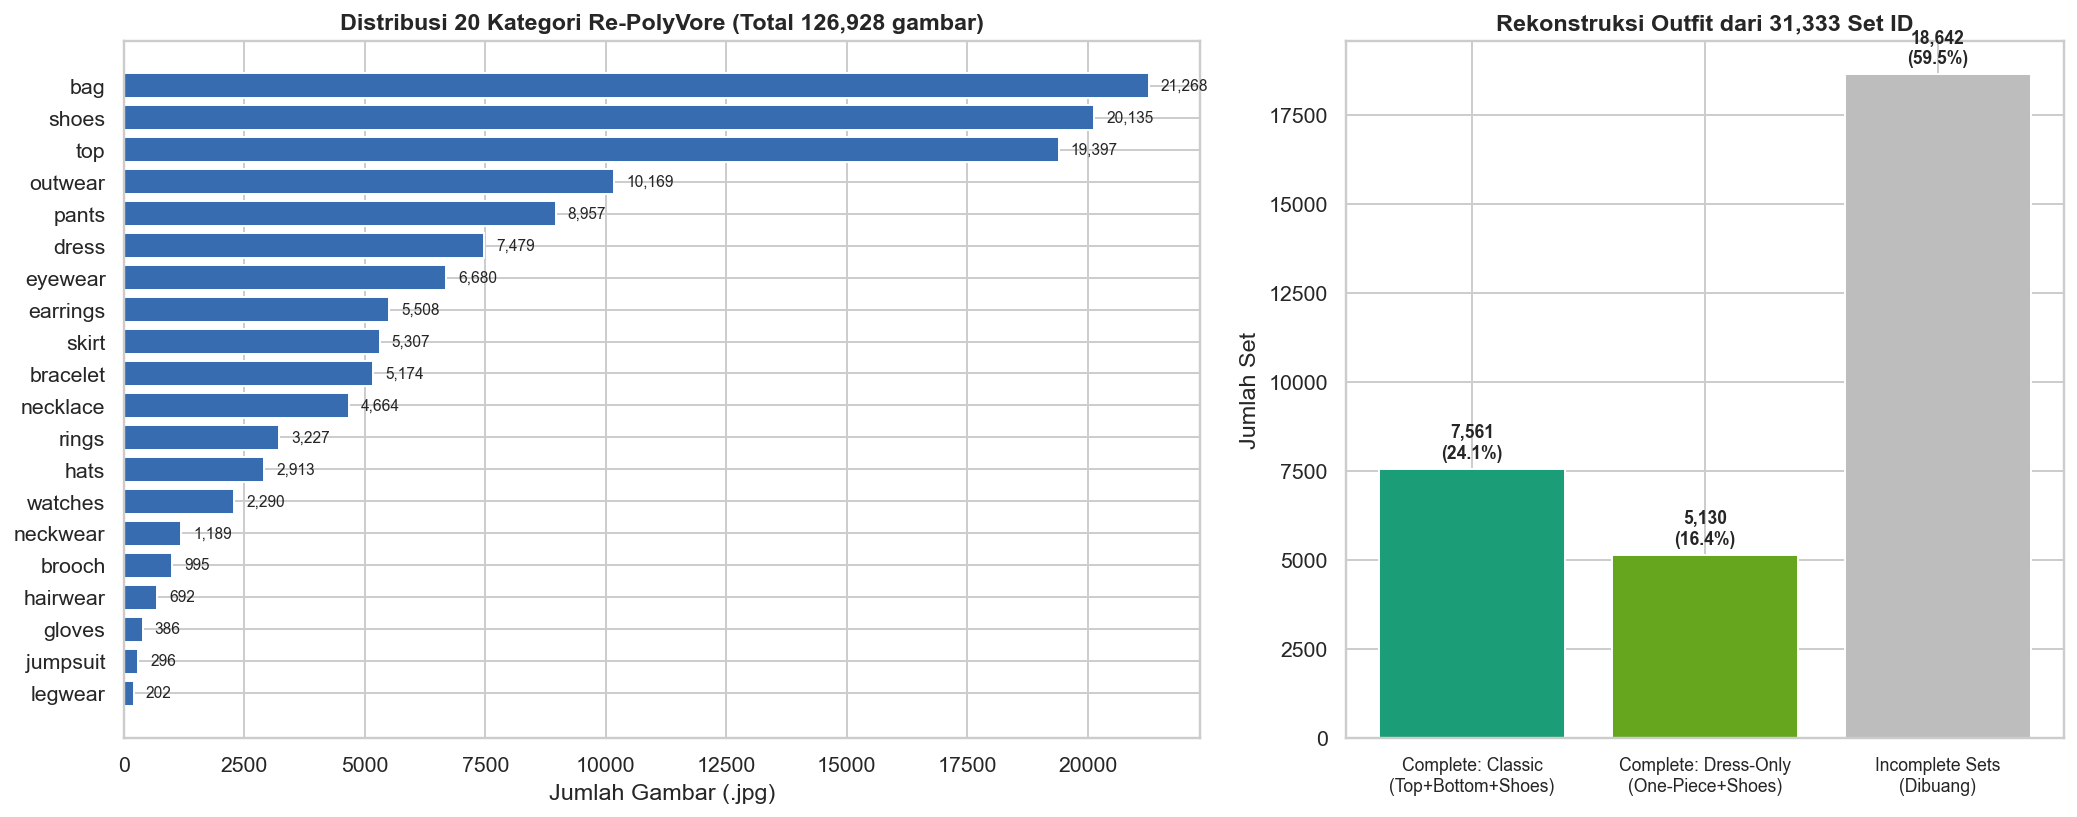

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/eda_polyvore_dist.png


In [3]:
# Visualisasi Inventaris Re-PolyVore & Rekonstruksi Template Outfit
p_sum = eda_summary["polyvore"]
cat_s = pd.Series(p_sum["category_counts"]).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=140, gridspec_kw={"width_ratios": [1.5, 1]})

axes[0].barh(cat_s.index, cat_s.values, color="#386cb0")
axes[0].set_title(f"Distribusi 20 Kategori Re-PolyVore (Total {p_sum['total_jpg']:,} gambar)", fontweight="bold")
axes[0].set_xlabel("Jumlah Gambar (.jpg)")
for i, v in enumerate(cat_s.values):
    axes[0].text(v + 250, i, f"{v:,}", va="center", fontsize=8)

classic_cnt = p_sum["complete_templates"] - p_sum["dress_only_templates"]
incomplete_cnt = p_sum["unique_set_ids"] - p_sum["complete_templates"]
tpl_labels = ["Complete: Classic\n(Top+Bottom+Shoes)", "Complete: Dress-Only\n(One-Piece+Shoes)", "Incomplete Sets\n(Dibuang)"]
tpl_vals = [classic_cnt, p_sum["dress_only_templates"], incomplete_cnt]
colors = ["#1b9e77", "#66a61e", "#bdbdbd"]
bars = axes[1].bar(tpl_labels, tpl_vals, color=colors)
axes[1].set_title(f"Rekonstruksi Outfit dari {p_sum['unique_set_ids']:,} Set ID", fontweight="bold")
axes[1].set_ylabel("Jumlah Set")
axes[1].tick_params(axis="x", labelsize=9)
for bar, v in zip(bars, tpl_vals):
    pct = v / p_sum["unique_set_ids"] * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 300, f"{v:,}\n({pct:.1f}%)", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig.savefig(PLOT_DIR / "eda_polyvore_dist.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "eda_polyvore_dist.png"))